<a href="https://colab.research.google.com/github/logonzalezsa/PPAE/blob/main/02_Cuadernos/PPAE_09_Metodo_Tres_Momentos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# PROGRAMACIÓN PARA ANÁLISIS DE ESTRUCTURAS

**Universidad Nacional de Colombia – Sede Palmira**  
**Programa Curricular de Ingeniería Agrícola**

---

## PPAE_09 — MÉTODO DE LOS TRES MOMENTOS

### Análisis de vigas continuas con extremos empotrados

**Aplicación del método de Clapeyron mediante programación en Python**

**Objetivo:** Desarrollar una herramienta computacional para determinar los momentos flectores internos en los apoyos de vigas continuas con ambos extremos empotrados, sometidas a cargas uniformemente distribuidas que pueden variar entre tramos y con diferentes momentos de inercia relativos.

**Alcance:** El cuaderno calcula exclusivamente los momentos flectores en los apoyos. La determinación de reacciones, fuerzas cortantes, momentos en los tramos y elaboración de diagramas de cortante y momento flector corresponde al análisis posterior que deberá realizar el estudiante.

---

**Elaborado por:**  
Luis Octavio González Salcedo  
Profesor Titular

**Curso:** Programación para Análisis de Estructuras  
**Periodo académico:** 2026-II



## 1. Fundamento del método de los tres momentos

El **método de los tres momentos**, también conocido como **teorema de Clapeyron**, permite analizar vigas continuas mediante ecuaciones que relacionan los momentos flectores internos en tres apoyos consecutivos.

Para formular cada ecuación se consideran:

- Tres apoyos consecutivos: $A$, $B$ y $C$.
- Dos tramos adyacentes, de longitudes $L_1$ y $L_2$.
- Los momentos flectores internos $M_A$, $M_B$ y $M_C$.
- Las cargas distribuidas $q_1$ y $q_2$.
- Los momentos de inercia $I_1$ e $I_2$.

Para tramos prismáticos, material con módulo de elasticidad constante y apoyos sin asentamientos, sometidos a cargas uniformemente distribuidas, la ecuación de los tres momentos es:

$$
\boxed{
\frac{M_A L_1}{I_1}
+
2M_B\left(\frac{L_1}{I_1}+\frac{L_2}{I_2}\right)
+
\frac{M_C L_2}{I_2}
=
-\frac{q_1L_1^3}{4I_1}
-\frac{q_2L_2^3}{4I_2}
}
$$

Esta expresión adopta momentos negativos para flexión de empotramiento o de apoyo (hogging), y cargas $q$ positivas hacia abajo.

### 1.1. Consideración de diferentes momentos de inercia

Cuando las secciones transversales de los tramos son diferentes, sus momentos de inercia también pueden serlo.

Si se toma un momento de inercia de referencia $I_{ref}$, podemos expresar:

$$
I_i=r_i I_{ref}
$$

donde $r_i$ representa el **momento de inercia relativo** del tramo.

Por ejemplo:

$$
I_1=2I_{ref},\qquad
I_2=I_{ref},\qquad
I_3=1.5I_{ref}
$$

Por tanto:

$$
r_1=2,\qquad r_2=1,\qquad r_3=1.5
$$

Al sustituir estas expresiones en las ecuaciones y cancelar el factor común $I_{ref}$, el sistema puede construirse utilizando únicamente los coeficientes relativos:

$$
\boxed{
\frac{M_A L_1}{r_1}
+
2M_B\left(\frac{L_1}{r_1}+\frac{L_2}{r_2}\right)
+
\frac{M_C L_2}{r_2}
=
-\frac{q_1L_1^3}{4r_1}
-\frac{q_2L_2^3}{4r_2}
}
$$

### 1.2. Condiciones de empotramiento

En este cuaderno se considerarán exclusivamente vigas continuas con **ambos extremos empotrados** y apoyos intermedios simples, sin asentamientos.

En los empotramientos, el giro de la sección transversal es nulo:

$$
\theta_A=0,\qquad \theta_D=0
$$

Estas condiciones permiten formular las ecuaciones adicionales necesarias para determinar los momentos en los apoyos extremos.

**Importante:** un empotramiento puede desarrollar un momento flector distinto de cero. Por tanto, no debe imponerse $M_A=0$ ni $M_D=0$.

### 1.3. Resultado del método

La solución del sistema de ecuaciones proporciona los momentos flectores internos en todos los apoyos de la viga continua.

Posteriormente, el estudiante deberá utilizar estos momentos para completar manualmente el análisis estructural:

- Determinación de reacciones.
- Cálculo de fuerzas cortantes.
- Localización de puntos donde la fuerza cortante es cero.
- Determinación de momentos flectores dentro de los tramos.
- Construcción de los diagramas de cortante y momento flector.

**El programa no reemplaza estas etapas del análisis estructural.**



## 2. Incorporación de los empotramientos extremos

En una viga continua con ambos extremos empotrados, los momentos flectores en los apoyos extremos son desconocidos y deben determinarse junto con los momentos de los apoyos intermedios.

Para incorporar estas condiciones en el método de los tres momentos, pueden utilizarse **tramos ficticios de longitud nula** en los extremos.

### 2.1. Empotramiento izquierdo

Consideremos el primer tramo real $AB$, de longitud $L_1$, carga uniformemente distribuida $q_1$ y momento de inercia relativo $r_1$.

Al incorporar un tramo ficticio de longitud nula a la izquierda del apoyo $A$, la ecuación de los tres momentos se reduce a:

$$
\boxed{
2M_A\frac{L_1}{r_1}
+
M_B\frac{L_1}{r_1}
=
-\frac{q_1L_1^3}{4r_1}
}
$$

Dividiendo por $L_1/r_1$:

$$
\boxed{
2M_A+M_B=-\frac{q_1L_1^2}{4}
}
$$

Esta ecuación representa la condición de giro nulo en el empotramiento izquierdo.

### 2.2. Empotramiento derecho

De manera semejante, para el último tramo real, comprendido entre los apoyos $Y$ y $Z$, se incorpora un tramo ficticio de longitud nula a la derecha del apoyo $Z$.

La ecuación correspondiente es:

$$
\boxed{
M_Y\frac{L_n}{r_n}
+
2M_Z\frac{L_n}{r_n}
=
-\frac{q_nL_n^3}{4r_n}
}
$$

Al simplificar:

$$
\boxed{
M_Y+2M_Z=-\frac{q_nL_n^2}{4}
}
$$

Esta ecuación representa la condición de giro nulo en el empotramiento derecho.

### 2.3. Número de ecuaciones del sistema

Para una viga continua de $n$ tramos existen $n+1$ apoyos y, por tanto, $n+1$ momentos de apoyo desconocidos.

El sistema se construye mediante:

- Una ecuación correspondiente al empotramiento izquierdo.
- $n-1$ ecuaciones de tres momentos para los apoyos intermedios.
- Una ecuación correspondiente al empotramiento derecho.

En consecuencia:

$$
\boxed{
1+(n-1)+1=n+1
}
$$

Se obtiene un sistema de $n+1$ ecuaciones con $n+1$ incógnitas.

### 2.4. Representación matricial

El sistema puede expresarse como:

$$
\boxed{
[K]\{M\}=\{P\}
}
$$

donde:

- $[K]$ es la matriz de coeficientes del método de los tres momentos.
- $\{M\}$ es el vector de momentos flectores desconocidos en los apoyos.
- $\{P\}$ es el vector de términos independientes asociados a las cargas distribuidas.

La matriz de coeficientes presenta una estructura **tridiagonal**, porque cada ecuación relaciona, como máximo, tres momentos de apoyo consecutivos.

Esta característica permitirá construir automáticamente el sistema mediante ciclos de programación, utilizando las longitudes, cargas y momentos de inercia relativos de cada tramo.



## 3. Ejemplo de aplicación: viga continua de tres tramos

Se considera una viga continua con cuatro apoyos, identificados como $A$, $B$, $C$ y $D$.

Los apoyos extremos $A$ y $D$ están empotrados, mientras que $B$ y $C$ son apoyos intermedios simples, sin asentamientos.

La viga está sometida a cargas uniformemente distribuidas, que pueden ser diferentes en cada tramo. También se consideran momentos de inercia relativos distintos.

### 3.1. Datos del ejemplo

| Tramo | Longitud $L$ (m) | Carga $q$ (kN/m) | Inercia relativa $r$ |
|---|---:|---:|---:|
| AB | 4 | 12 | 2.0 |
| BC | 5 | 18 | 1.0 |
| CD | 3 | 10 | 1.5 |

Los momentos flectores desconocidos son:

$$
\boxed{
\{M\}=
\begin{Bmatrix}
M_A\\
M_B\\
M_C\\
M_D
\end{Bmatrix}
}
$$

Se adopta el convenio de momentos positivos para flexión sagante y negativos para flexión de apoyo.

### 3.2. Ecuación del empotramiento izquierdo

Para el tramo $AB$:

$$
2M_A+M_B=-\frac{q_1L_1^2}{4}
$$

Sustituyendo:

$$
2M_A+M_B=-\frac{12(4)^2}{4}
$$

$$
\boxed{2M_A+M_B=-48}
$$

### 3.3. Ecuación del apoyo intermedio B

Se consideran los tramos $AB$ y $BC$:

$$
\frac{L_1}{r_1}M_A+
2\left(\frac{L_1}{r_1}+\frac{L_2}{r_2}\right)M_B+
\frac{L_2}{r_2}M_C
=
-\frac{q_1L_1^3}{4r_1}
-\frac{q_2L_2^3}{4r_2}
$$

Sustituyendo:

$$
2M_A+14M_B+5M_C=-610.5
$$

### 3.4. Ecuación del apoyo intermedio C

Se consideran los tramos $BC$ y $CD$:

$$
\frac{L_2}{r_2}M_B+
2\left(\frac{L_2}{r_2}+\frac{L_3}{r_3}\right)M_C+
\frac{L_3}{r_3}M_D
=
-\frac{q_2L_2^3}{4r_2}
-\frac{q_3L_3^3}{4r_3}
$$

Sustituyendo:

$$
5M_B+14M_C+2M_D=-607.5
$$

### 3.5. Ecuación del empotramiento derecho

Para el tramo $CD$:

$$
M_C+2M_D=-\frac{q_3L_3^2}{4}
$$

Sustituyendo:

$$
\boxed{M_C+2M_D=-22.5}
$$

### 3.6. Sistema matricial

Las cuatro ecuaciones se organizan como:

$$
\boxed{
\begin{bmatrix}
2 & 1 & 0 & 0\\
2 & 14 & 5 & 0\\
0 & 5 & 14 & 2\\
0 & 0 & 1 & 2
\end{bmatrix}
\begin{Bmatrix}
M_A\\
M_B\\
M_C\\
M_D
\end{Bmatrix}
=
\begin{Bmatrix}
-48\\
-610.5\\
-607.5\\
-22.5
\end{Bmatrix}
}
$$

La matriz es tridiagonal porque cada ecuación contiene como máximo tres momentos consecutivos.

**Este sistema será nuestro ejemplo de verificación.** Posteriormente, el programa construirá automáticamente la matriz y el vector de términos independientes a partir de los datos de cada tramo.



### 3.2. Esquema estructural de la viga

La siguiente figura representa la viga continua del ejemplo, con sus tres tramos, cuatro apoyos, cargas uniformemente distribuidas y momentos de inercia relativos.

Los apoyos extremos $A$ y $D$ están empotrados, mientras que los apoyos intermedios $B$ y $C$ son simples.

A partir de esta configuración se determinarán los cuatro momentos flectores internos:

$$
\{M\}=
\begin{Bmatrix}
M_A\\M_B\\M_C\\M_D
\end{Bmatrix}
$$


In [ ]:

# ============================================================
# PPAE_09 - ESQUEMA ESTRUCTURAL DEL EJEMPLO
# Viga continua de tres tramos con extremos empotrados
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# 1. DATOS DEL EJEMPLO
L = np.array([4.0, 5.0, 3.0])      # Longitudes (m)
q = np.array([12.0, 18.0, 10.0])    # Cargas (kN/m)
r = np.array([2.0, 1.0, 1.5])      # Inercias relativas

# Posiciones de los apoyos
x = np.concatenate(([0.0], np.cumsum(L)))
n = len(L)

fig, ax = plt.subplots(figsize=(13, 5))

# 2. VIGA
ax.plot([x[0], x[-1]], [0, 0],
        color="steelblue", linewidth=6,
        solid_capstyle="butt", zorder=5)

# 3. EMPOTRAMIENTOS EXTREMOS
for posicion, lado in [(x[0], -1), (x[-1], 1)]:
    ax.plot([posicion, posicion], [-0.45, 0.55],
            color="black", linewidth=3)
    for yy in np.arange(-0.45, 0.55, 0.13):
        ax.plot([posicion, posicion + lado*0.23],
                [yy, yy-0.13],
                color="black", linewidth=1)

# 4. APOYOS INTERMEDIOS SIMPLES
for posicion in x[1:-1]:
    triangulo = Polygon(
        [[posicion, -0.06],
         [posicion-0.23, -0.38],
         [posicion+0.23, -0.38]],
        closed=True,
        facecolor="white",
        edgecolor="black",
        linewidth=1.8
    )
    ax.add_patch(triangulo)
    ax.plot([posicion-0.32, posicion+0.32],
            [-0.40, -0.40],
            color="black", linewidth=2)

# 5. CARGAS UNIFORMEMENTE DISTRIBUIDAS
for i in range(n):
    xi, xf = x[i], x[i+1]
    posiciones = np.linspace(xi+0.20, xf-0.20, 9)

    ax.plot([posiciones[0], posiciones[-1]],
            [1.05, 1.05], color="firebrick", linewidth=1.5)

    for xp in posiciones:
        ax.annotate(
            "", xy=(xp, 0.10), xytext=(xp, 1.05),
            arrowprops=dict(
                arrowstyle="-|>",
                color="firebrick",
                lw=1.4,
                mutation_scale=13
            )
        )

    ax.text((xi+xf)/2, 1.25,
            f"q{i+1} = {q[i]:g} kN/m",
            ha="center", color="firebrick",
            fontsize=12, fontweight="bold")

# 6. IDENTIFICACIÓN DE APOYOS
for i, posicion in enumerate(x):
    ax.text(posicion, -0.62, chr(65+i),
            ha="center", fontsize=13,
            fontweight="bold")

# 7. LONGITUDES E INERCIAS RELATIVAS
for i in range(n):
    xi, xf = x[i], x[i+1]
    xm = (xi+xf)/2

    ax.annotate(
        "", xy=(xi, -1.0), xytext=(xf, -1.0),
        arrowprops=dict(arrowstyle="<->", lw=1.2)
    )

    ax.text(xm, -0.91,
            f"L{i+1} = {L[i]:g} m",
            ha="center", va="bottom", fontsize=11)

    ax.text(xm, -1.38,
            f"I{i+1} = {r[i]:g} Iref",
            ha="center", fontsize=11,
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="wheat",
                edgecolor="goldenrod"
            ))

# 8. PRESENTACIÓN
ax.set_xlim(-0.65, x[-1]+0.65)
ax.set_ylim(-1.8, 1.8)
ax.set_aspect("auto")
ax.axis("off")

ax.set_title(
    "Viga continua de tres tramos con extremos empotrados",
    fontsize=14, fontweight="bold", pad=20
)

plt.tight_layout()
plt.show()


In [3]:

# ============================================================
# PPAE_09 - MÉTODO DE LOS TRES MOMENTOS
# APLICACIÓN INDIVIDUAL
# Vigas continuas con ambos extremos empotrados
# ============================================================

import numpy as np

print("=" * 60)
print("MÉTODO DE LOS TRES MOMENTOS - CLAPEYRON")
print("VIGA CONTINUA CON EXTREMOS EMPOTRADOS")
print("=" * 60)

# 1. NÚMERO DE TRAMOS
n = int(input("\nIngrese el número de tramos de la viga: "))

if n < 1:
    raise ValueError("La viga debe tener al menos un tramo.")

# 2. INGRESO DE DATOS
L = []
q = []
r = []

for i in range(n):
    print(f"\n--- TRAMO {i+1} ---")

    longitud = float(input("Longitud L (m): "))
    carga = float(input("Carga distribuida q (kN/m): "))
    inercia = float(input("Inercia relativa r = I/Iref: "))

    if longitud <= 0 or inercia <= 0:
        raise ValueError(
            "La longitud y la inercia relativa deben ser positivas."
        )

    if carga < 0:
        raise ValueError(
            "La carga debe ser positiva o cero (sentido hacia abajo)."
        )

    L.append(longitud)
    q.append(carga)
    r.append(inercia)

L = np.array(L)
q = np.array(q)
r = np.array(r)

# 3. INICIALIZACIÓN DEL SISTEMA
numero_apoyos = n + 1

K = np.zeros((numero_apoyos, numero_apoyos))
P = np.zeros(numero_apoyos)

# 4. EMPOTRAMIENTO IZQUIERDO
K[0, 0] = 2.0
K[0, 1] = 1.0
P[0] = -q[0] * L[0]**2 / 4.0

# 5. ECUACIONES DE APOYOS INTERMEDIOS
for i in range(1, n):

    K[i, i-1] = L[i-1] / r[i-1]

    K[i, i] = 2.0 * (
        L[i-1] / r[i-1] + L[i] / r[i]
    )

    K[i, i+1] = L[i] / r[i]

    P[i] = -(
        q[i-1] * L[i-1]**3 / (4.0 * r[i-1])
        + q[i] * L[i]**3 / (4.0 * r[i])
    )

# 6. EMPOTRAMIENTO DERECHO
K[n, n-1] = 1.0
K[n, n] = 2.0
P[n] = -q[n-1] * L[n-1]**2 / 4.0

# 7. PRESENTACIÓN DEL SISTEMA
print("\n" + "=" * 60)
print("MATRIZ DE COEFICIENTES K")
print("=" * 60)
print(K)

print("\nVECTOR DE TÉRMINOS INDEPENDIENTES P")
print(P)

# 8. SOLUCIÓN
M = np.linalg.solve(K, P)

# 9. RESULTADOS
print("\n" + "=" * 60)
print("MOMENTOS FLECTORES EN LOS APOYOS")
print("=" * 60)

for i, momento in enumerate(M):
    print(f"Apoyo {i+1}: M = {momento:.4f} kN·m")

print("\nConvención: momento sagante positivo.")
print("Momentos negativos: flexión de apoyo.")
print("\nEl análisis de reacciones y diagramas")
print("debe realizarlo el estudiante.")


# 10. TABLA RESUMEN DE LOS DATOS DEL ESTUDIANTE

print("\n" + "=" * 65)
print("RESUMEN DE DATOS DE LA VIGA ANALIZADA")
print("=" * 65)

print(f"{'Tramo':<12}{'L (m)':>12}{'q (kN/m)':>15}{'I/Iref':>12}")
print("-" * 65)

for i in range(n):
    print(
        f"{i+1:<12}"
        f"{L[i]:>12.2f}"
        f"{q[i]:>15.2f}"
        f"{r[i]:>12.2f}"
    )

print("-" * 65)
print(f"Número de tramos: {n}")
print(f"Número de apoyos: {n+1}")
print("Condiciones: ambos extremos empotrados")


MÉTODO DE LOS TRES MOMENTOS - CLAPEYRON
VIGA CONTINUA CON EXTREMOS EMPOTRADOS

Ingrese el número de tramos de la viga: 3

--- TRAMO 1 ---
Longitud L (m): 4
Carga distribuida q (kN/m): 12
Inercia relativa r = I/Iref: 2

--- TRAMO 2 ---
Longitud L (m): 5
Carga distribuida q (kN/m): 18
Inercia relativa r = I/Iref: 1

--- TRAMO 3 ---
Longitud L (m): 3
Carga distribuida q (kN/m): 10
Inercia relativa r = I/Iref: 1.5

MATRIZ DE COEFICIENTES K
[[ 2.  1.  0.  0.]
 [ 2. 14.  5.  0.]
 [ 0.  5. 14.  2.]
 [ 0.  0.  1.  2.]]

VECTOR DE TÉRMINOS INDEPENDIENTES P
[ -48.  -658.5 -607.5  -22.5]

MOMENTOS FLECTORES EN LOS APOYOS
Apoyo 1: M = -6.5990 kN·m
Apoyo 2: M = -34.8021 kN·m
Apoyo 3: M = -31.6146 kN·m
Apoyo 4: M = 4.5573 kN·m

Convención: momento sagante positivo.
Momentos negativos: flexión de apoyo.

El análisis de reacciones y diagramas
debe realizarlo el estudiante.

RESUMEN DE DATOS DE LA VIGA ANALIZADA
Tramo              L (m)       q (kN/m)      I/Iref
---------------------------------------

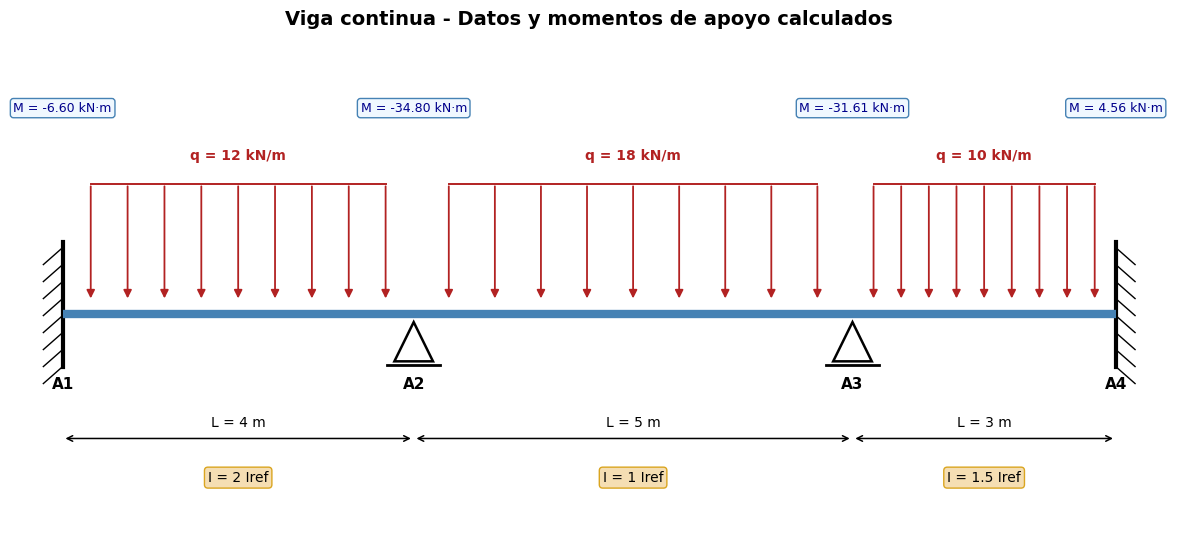

In [4]:

# ============================================================
# PPAE_09 - ESQUEMA AUTOMÁTICO DE LA VIGA DEL ESTUDIANTE
# Utiliza los datos y resultados de la celda anterior
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# Posiciones de los apoyos
x = np.concatenate(([0.0], np.cumsum(L)))
n = len(L)

fig, ax = plt.subplots(figsize=(max(12, 3*n), 5.5))

# 1. DIBUJO DE LA VIGA
ax.plot([x[0], x[-1]], [0, 0],
        color="steelblue", linewidth=6,
        solid_capstyle="butt", zorder=5)

# 2. EMPOTRAMIENTOS EXTREMOS
for posicion, lado in [(x[0], -1), (x[-1], 1)]:
    ax.plot([posicion, posicion], [-0.40, 0.55],
            color="black", linewidth=3)

    for yy in np.arange(-0.40, 0.55, 0.13):
        ax.plot([posicion, posicion + lado*0.22],
                [yy, yy-0.13], color="black", linewidth=1)

# 3. APOYOS INTERMEDIOS
for posicion in x[1:-1]:
    triangulo = Polygon(
        [[posicion, -0.06],
         [posicion-0.22, -0.36],
         [posicion+0.22, -0.36]],
        closed=True, facecolor="white",
        edgecolor="black", linewidth=1.8
    )
    ax.add_patch(triangulo)
    ax.plot([posicion-0.30, posicion+0.30],
            [-0.39, -0.39], color="black", linewidth=2)

# 4. CARGAS, LONGITUDES E INERCIAS
for i in range(n):
    xi, xf = x[i], x[i+1]
    xm = (xi + xf)/2

    # Flechas de carga distribuida
    posiciones = np.linspace(
        xi + 0.08*L[i], xf - 0.08*L[i], 9
    )

    for xp in posiciones:
        ax.annotate(
            "", xy=(xp, 0.10), xytext=(xp, 1.0),
            arrowprops=dict(
                arrowstyle="-|>", color="firebrick",
                lw=1.3, mutation_scale=12
            )
        )

    ax.plot([posiciones[0], posiciones[-1]],
            [1.0, 1.0], color="firebrick", linewidth=1.4)

    ax.text(xm, 1.18, f"q = {q[i]:g} kN/m",
            ha="center", color="firebrick",
            fontsize=10, fontweight="bold")

    # Longitud
    ax.annotate(
        "", xy=(xi, -0.95), xytext=(xf, -0.95),
        arrowprops=dict(arrowstyle="<->", lw=1.1)
    )

    ax.text(xm, -0.86, f"L = {L[i]:g} m",
            ha="center", fontsize=10)

    # Inercia relativa
    ax.text(xm, -1.28, f"I = {r[i]:g} Iref",
            ha="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.25",
                      facecolor="wheat",
                      edgecolor="goldenrod"))

# 5. APOYOS Y MOMENTOS CALCULADOS
for i, posicion in enumerate(x):

    apoyo = f"A{i+1}"

    ax.text(posicion, -0.57, apoyo,
            ha="center", fontsize=11,
            fontweight="bold")

    ax.text(posicion, 1.55,
            f"M = {M[i]:.2f} kN·m",
            ha="center", fontsize=9,
            color="darkblue",
            bbox=dict(boxstyle="round,pad=0.25",
                      facecolor="aliceblue",
                      edgecolor="steelblue"))

# 6. PRESENTACIÓN
ax.set_xlim(-0.6, x[-1]+0.6)
ax.set_ylim(-1.65, 2.0)
ax.axis("off")

ax.set_title(
    "Viga continua - Datos y momentos de apoyo calculados",
    fontsize=14, fontweight="bold", pad=20
)

plt.tight_layout()
plt.show()



---

## 5. Actividad complementaria: análisis estructural de la viga continua

Una vez determinados los momentos flectores en los apoyos mediante el método de los tres momentos, el estudiante deberá **completar manualmente el análisis estructural de la viga continua**.

Los momentos obtenidos mediante el programa constituyen las condiciones de borde para analizar individualmente cada tramo de la viga.

### 5.1. Determinación de las reacciones

Para cada tramo, el estudiante deberá elaborar su correspondiente **diagrama de cuerpo libre**, considerando:

- La carga uniformemente distribuida que actúa sobre el tramo.
- Los momentos flectores internos calculados en sus extremos.
- Las fuerzas verticales transmitidas por los apoyos.

Mediante las ecuaciones de equilibrio estático:

$$
\sum F_y=0
$$

$$
\sum M=0
$$

Se determinarán las fuerzas cortantes en los extremos de cada tramo y, posteriormente, las reacciones verticales de los apoyos de la viga continua.

### 5.2. Cálculo de las fuerzas cortantes

Para cada tramo se establecerá la ecuación de fuerza cortante en función de la distancia $x$, medida desde su extremo izquierdo:

$$
\boxed{V(x)=V_A-qx}
$$

donde:

- $V(x)$: fuerza cortante en una sección situada a una distancia $x$.
- $V_A$: fuerza cortante interna inmediatamente a la derecha del extremo izquierdo del tramo.
- $q$: carga uniformemente distribuida.
- $x$: distancia medida desde el extremo izquierdo.

La ecuación se aplicará individualmente a cada tramo, considerando sus respectivas cargas y fuerzas cortantes iniciales.

### 5.3. Localización de los puntos de cortante nulo

El estudiante deberá determinar las posiciones donde la fuerza cortante se anula:

$$
V(x)=0
$$

Para un tramo con carga uniformemente distribuida distinta de cero:

$$
\boxed{x=\frac{V_A}{q}}
$$

Se verificará que la distancia calculada pertenezca al tramo analizado:

$$
0\leq x\leq L
$$

También deberá identificarse si la fuerza cortante cambia de signo al atravesar dicho punto.

**Importante:** Los puntos donde la fuerza cortante cambia de signo pueden corresponder a máximos o mínimos locales del momento flector. También deben examinarse los extremos de cada tramo y las discontinuidades de cortante en los apoyos.

### 5.4. Determinación de los momentos flectores entre apoyos

Para cada tramo se establecerá la ecuación del momento flector:

$$
\boxed{M(x)=M_A+V_Ax-\frac{qx^2}{2}}
$$

donde $M_A$ corresponde al momento flector interno en el extremo izquierdo del tramo, calculado mediante el método de los tres momentos.

El estudiante deberá:

1. Formular la ecuación $M(x)$ de cada tramo.
2. Verificar que los momentos calculados en los extremos coincidan con los obtenidos mediante el programa.
3. Evaluar los momentos en los puntos donde la fuerza cortante es cero.
4. Identificar los valores máximos y mínimos del momento flector.
5. Determinar, cuando corresponda, las posiciones donde el momento flector cambia de signo (puntos de contraflexión).

### 5.5. Construcción de los diagramas

Con los resultados anteriores se elaborarán:

- El diagrama de fuerza cortante de toda la viga.
- El diagrama de momento flector de toda la viga.

Los diagramas deberán indicar los valores significativos, las distancias correspondientes y las unidades utilizadas.

### 5.6. Verificación de resultados

Como comprobación final, el estudiante deberá verificar:

- El equilibrio global de la viga continua.
- La correspondencia entre las fuerzas cortantes y las cargas aplicadas.
- La coincidencia de los momentos flectores en los apoyos con los resultados computacionales.
- La relación entre los puntos de cortante nulo y los valores extremos del momento flector.
- La coherencia de los signos y la forma de los diagramas.

---

## 6. Producto final del ejercicio

Cada estudiante deberá presentar:

1. **El cuaderno de Google Colab ejecutado**, con los datos de su viga, la matriz de coeficientes, los momentos de apoyo y el esquema estructural.
2. **El desarrollo manual del análisis**, incluyendo reacciones, ecuaciones de cortante y momento flector, localización de puntos críticos y diagramas correspondientes.
3. **Una breve interpretación de los resultados**, destacando el comportamiento de los momentos flectores en los apoyos y en los tramos.

### Reflexión final

La programación constituye una herramienta de apoyo para resolver sistemas de ecuaciones y facilitar el análisis de estructuras. Sin embargo, la interpretación de los resultados y la verificación del comportamiento estructural requieren el conocimiento de los principios fundamentales de la mecánica.

**El propósito del ejercicio no es reemplazar el análisis estructural, sino integrar la programación con los conocimientos adquiridos en Estática, Resistencia de Materiales y Análisis de Estructuras.**
